# Requisitos

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Carregamento dos dados

In [33]:
df_train = pd.read_csv("../dados/treino.csv")
df_val = pd.read_csv("../dados/validacao.csv")

In [34]:
df_train["date"] = pd.to_datetime(df_train["date"])
df_val["date"] = pd.to_datetime(df_val["date"])

# Feature Engineering

In [35]:
window = 12

# Media movel do conjunto de treino
df_train["store_total_mean_movel"] = df_train['store_total'].rolling(window=window).mean().bfill()
df_train["FOODS_mean_movel"] = df_train['FOODS'].rolling(window=window).mean().bfill()
df_train["HOBBIES_mean_movel"] = df_train['HOBBIES'].rolling(window=window).mean().bfill()

# Media movel do conjunto de validacao
df_val["store_total_mean_movel"] = df_val['store_total'].rolling(window=window).mean().bfill()
df_val["FOODS_mean_movel"] = df_val['FOODS'].rolling(window=window).mean().bfill()
df_val["HOBBIES_mean_movel"] = df_val['HOBBIES'].rolling(window=window).mean().bfill()

In [46]:
df_train["week"] = df_train["date"].dt.strftime('%U')
df_train["month"] = df_train["date"].dt.month
df_train["year"] = df_train["date"].dt.year
df_train["weekday"] = df_train["date"].dt.weekday

df_val["week"] = df_val["date"].dt.strftime('%U')
df_val["month"] = df_val["date"].dt.month
df_val["year"] = df_val["date"].dt.year
df_val["weekday"] = df_val["date"].dt.weekday

In [47]:
df_train

,date,store_total,FOODS,HOBBIES,store_total_mean_movel,FOODS_mean_movel,HOBBIES_mean_movel,mes,month,week,year,weekday
0,2011-01-29,4337,3239,556,3529.500000,2644.916667,451.833333,1,1,04,2011,5
1,2011-01-30,4155,3137,498,3529.500000,2644.916667,451.833333,1,1,05,2011,6
2,2011-01-31,2816,2008,415,3529.500000,2644.916667,451.833333,1,1,05,2011,0
3,2011-02-01,3051,2258,392,3529.500000,2644.916667,451.833333,2,2,05,2011,1
4,2011-02-02,2630,2032,268,3529.500000,2644.916667,451.833333,2,2,05,2011,2
...,...,...,...,...,...,...,...,...,...,...,...,...
1880,2016-03-23,3770,2554,454,4489.250000,2962.666667,512.916667,3,3,12,2016,2
1881,2016-03-24,3970,2681,474,4325.666667,2871.666667,490.500000,3,3,12,2016,3
1882,2016-03-25,4904,3421,446,4280.500000,2857.083333,477.916667,3,3,12,2016,4
1883,2016-03-26,6139,4251,610,4442.916667,2980.083333,490.333333,3,3,12,2016,5


# Visualização das séries

In [27]:
df_train.describe()

,date,store_total,FOODS,HOBBIES,store_total_mean_movel,FOODS_mean_movel,HOBBIES_mean_movel
count,1885,1885.000000,1885.000000,1885.000000,1885.000000,1885.000000,1885.000000
mean,2013-08-28 00:00:00,4016.053581,2809.633952,457.095491,4012.292617,2807.680725,457.001547
min,2011-01-29 00:00:00,0.000000,0.000000,0.000000,2550.166667,1745.416667,240.833333
25%,2012-05-14 00:00:00,3344.000000,2319.000000,373.000000,3654.666667,2594.083333,414.083333
50%,2013-08-28 00:00:00,3899.000000,2710.000000,458.000000,4129.416667,2853.333333,462.833333
75%,2014-12-12 00:00:00,4627.000000,3262.000000,535.000000,4427.666667,3072.416667,511.500000
max,2016-03-27 00:00:00,6948.000000,5016.000000,953.000000,5142.416667,3842.333333,623.250000
std,NaN,990.025324,701.179632,123.562642,545.690919,371.405925,73.521124


[Text(0.5, 1.0, 'HOBBIES')]

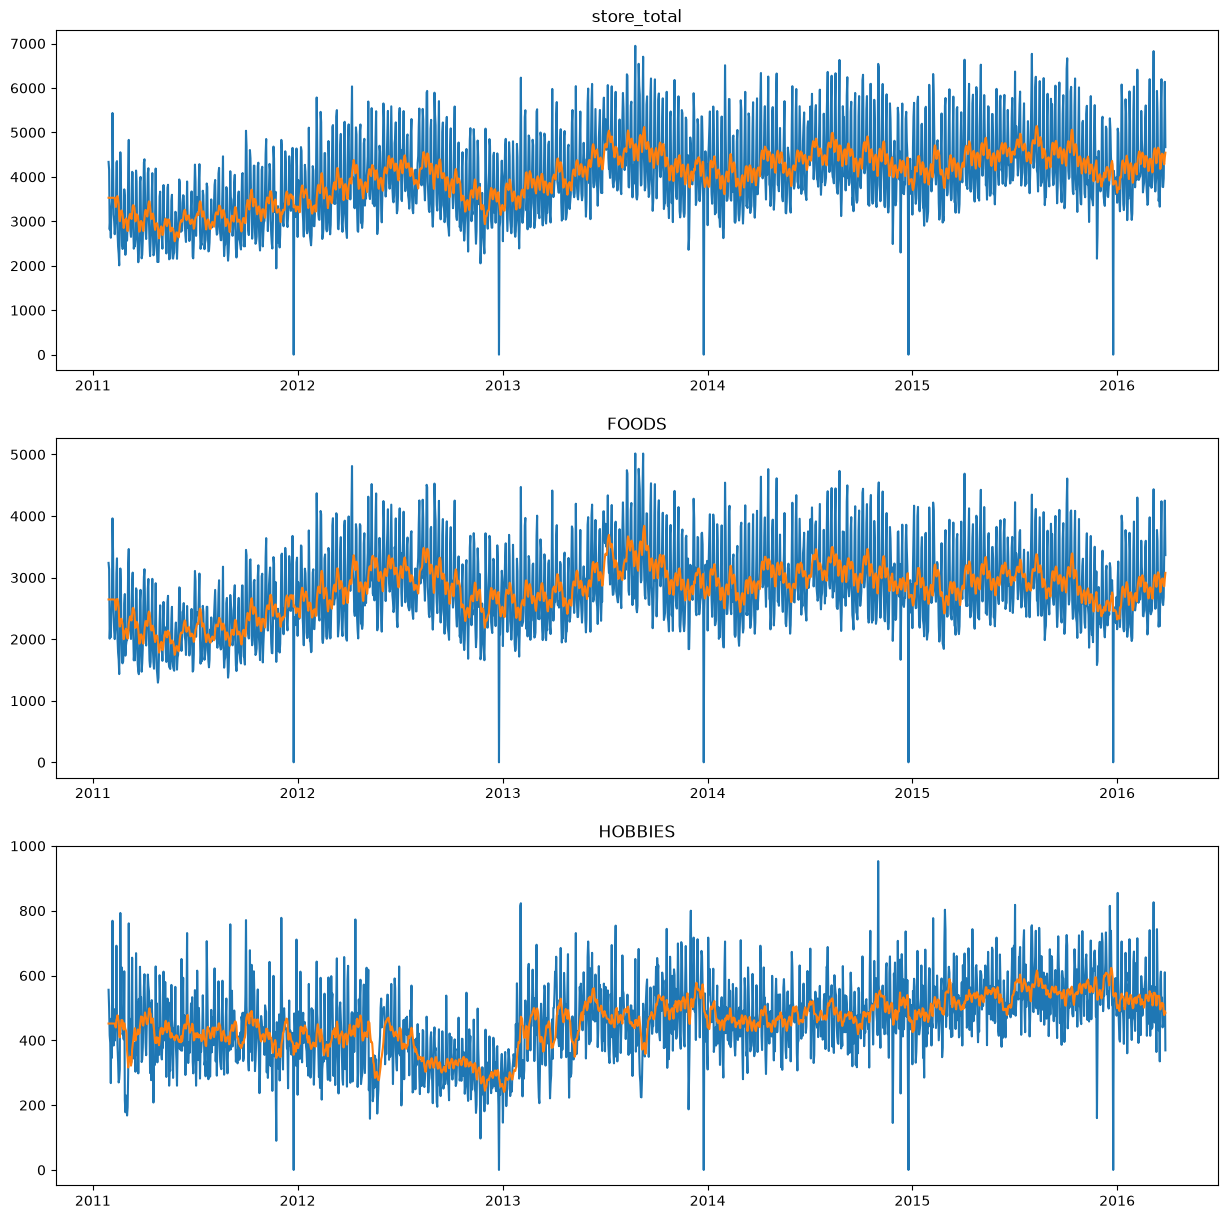

In [28]:
fig, axes = plt.subplots(3, 1, figsize=(15, 15))
axes = np.ravel(axes)
axes[0].plot(df_train["date"], df_train["store_total"])
axes[0].plot(df_train["date"], df_train["store_total_mean_movel"])
axes[0].set(title="store_total")

axes[1].plot(df_train["date"], df_train["FOODS"])
axes[1].plot(df_train["date"], df_train["FOODS_mean_movel"])
axes[1].set(title="FOODS")

axes[2].plot(df_train["date"], df_train["HOBBIES"])
axes[2].plot(df_train["date"], df_train["HOBBIES_mean_movel"])
axes[2].set(title="HOBBIES")
